# Practical Session 2: Standardized PCA

**Machine Learning — 1st-year Master’s degree**

This notebook implements principal component analysis (PCA) from scratch and checks it against `sklearn.decomposition.PCA`. The input variables are standardized with the sample standard deviation (`ddof=1`), so the covariance matrix of the standardized variables is their correlation matrix.

## 1. Load and inspect the data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# Rows are students and columns are subjects.
grades = pd.DataFrame(
    {
        "Mathematics": [12, 15, 8, 17, 10, 14],
        "Statistics": [11, 14, 9, 16, 12, 15],
        "Programming": [14, 16, 10, 18, 11, 13],
        "Algorithms": [13, 15, 9, 17, 10, 14],
    },
    index=["S1", "S2", "S3", "S4", "S5", "S6"],
)
grades.index.name = "Student"

display(grades)
print("Dimensions (students, subjects):", grades.shape)
display(grades.describe())

,Mathematics,Statistics,Programming,Algorithms
Student,,,,
S1,12,11,14,13
S2,15,14,16,15
S3,8,9,10,9
S4,17,16,18,17
S5,10,12,11,10
S6,14,15,13,14


Dimensions (students, subjects): (6, 4)


,Mathematics,Statistics,Programming,Algorithms
count,6.000000,6.000000,6.000000,6.00000
mean,12.666667,12.833333,13.666667,13.00000
std,3.326660,2.639444,3.011091,3.03315
min,8.000000,9.000000,10.000000,9.00000
25%,10.500000,11.250000,11.500000,10.75000
50%,13.000000,13.000000,13.500000,13.50000
75%,14.750000,14.750000,15.500000,14.75000
max,17.000000,16.000000,18.000000,17.00000


## Part A — Standardized PCA from scratch

### 2. Standardize the variables and form the correlation matrix

In [2]:
means = grades.mean(axis=0)
stds = grades.std(axis=0, ddof=1)
Z = (grades - means) / stds

print("Column means after standardization:")
display(Z.mean().to_frame("mean"))
print("Column sample standard deviations after standardization:")
display(Z.std(ddof=1).to_frame("std"))

correlation = Z.corr()
print("Correlation matrix of the standardized variables:")
display(correlation)

Column means after standardization:


,mean
Mathematics,1.757853e-16
Statistics,-2.220446e-16
Programming,2.220446e-16
Algorithms,1.850372e-17


Column sample standard deviations after standardization:


,std
Mathematics,1.0
Statistics,1.0
Programming,1.0
Algorithms,1.0


Correlation matrix of the standardized variables:


,Mathematics,Statistics,Programming,Algorithms
Mathematics,1.000000,0.926291,0.945072,0.991055
Statistics,0.926291,1.000000,0.771721,0.874363
Programming,0.945072,0.771721,1.000000,0.963529
Algorithms,0.991055,0.874363,0.963529,1.000000


### 3. Eigen-decomposition and ordering

The correlation matrix is symmetric, so `numpy.linalg.eigh` is appropriate. Its eigenvalues are returned in ascending order; we reverse that order and apply the same permutation to the eigenvectors.

In [3]:
eigenvalues_raw, eigenvectors_raw = np.linalg.eigh(correlation.to_numpy())
order = np.argsort(eigenvalues_raw)[::-1]
eigenvalues = eigenvalues_raw[order]
eigenvectors = eigenvectors_raw[:, order]

components = [f"PC{i}" for i in range(1, len(eigenvalues) + 1)]
eigenvalue_table = pd.DataFrame(
    {"Eigenvalue": eigenvalues,
     "Explained variance ratio": eigenvalues / eigenvalues.sum(),
     "Cumulative explained variance": np.cumsum(eigenvalues / eigenvalues.sum())},
    index=components,
)
print("Ordered eigenvalues and variance proportions:")
display(eigenvalue_table)
print("Ordered eigenvectors (columns correspond to PCs):")
display(pd.DataFrame(eigenvectors, index=grades.columns, columns=components))

Ordered eigenvalues and variance proportions:


,Eigenvalue,Explained variance ratio,Cumulative explained variance
PC1,3.739727,0.934932,0.934932
PC2,0.240228,0.060057,0.994989
PC3,0.019117,0.004779,0.999768
PC4,0.000927,0.000232,1.000000


Ordered eigenvectors (columns correspond to PCs):


,PC1,PC2,PC3,PC4
Mathematics,-0.516661,0.031968,0.209313,0.829594
Statistics,-0.477046,0.782218,-0.314901,-0.247789
Programming,-0.492822,-0.592169,-0.624880,-0.126442
Algorithms,-0.512460,-0.190916,0.683045,-0.484134


### 4. Keep two components and project the students

In [4]:
n_components = 2
loadings_2 = eigenvectors[:, :n_components]
scores_scratch = Z.to_numpy() @ loadings_2
scores_scratch = pd.DataFrame(
    scores_scratch,
    index=grades.index,
    columns=["PC1", "PC2"],
)

scratch_ratio = eigenvalues[:n_components] / eigenvalues.sum()
scratch_cumulative = np.cumsum(eigenvalues / eigenvalues.sum())
print("Student coordinates from scratch:")
display(scores_scratch)
print("Explained variance ratio (first two PCs):", scratch_ratio)
print("Cumulative explained variance (all PCs):", scratch_cumulative)
print(f"Variance retained by the first two PCs: {scratch_ratio.sum() * 100:.2f}%")

Student coordinates from scratch:


,PC1,PC2
Student,,
S1,0.380335,-0.615282
S2,-1.293049,-0.216593
S3,2.693534,-0.208012
S4,-2.630385,-0.123871
S5,1.508082,0.440673
S6,-0.658517,0.723085


Explained variance ratio (first two PCs): [0.93493183 0.06005712]
Cumulative explained variance (all PCs): [0.93493183 0.99498895 0.99976822 1.        ]
Variance retained by the first two PCs: 99.50%


## Part B — Standardized PCA with Scikit-learn

The input to `PCA` is already standardized, so no second scaler is applied. Fit all four components to compare the full eigenvalue spectrum; use the first two coordinates for the requested reduction.

In [5]:
pca = PCA()  # all components, for a complete comparison
scores_sklearn_all = pca.fit_transform(Z)
scores_sklearn = pd.DataFrame(
    scores_sklearn_all[:, :n_components],
    index=grades.index,
    columns=["PC1", "PC2"],
)

print("Student coordinates from Scikit-learn (first two PCs):")
display(scores_sklearn)
print("Explained variance ratios:", pca.explained_variance_ratio_)
print("Cumulative explained variance:", np.cumsum(pca.explained_variance_ratio_))
print(f"Variance retained by the first two PCs: {pca.explained_variance_ratio_[:2].sum() * 100:.2f}%")

Student coordinates from Scikit-learn (first two PCs):


,PC1,PC2
Student,,
S1,-0.380335,-0.615282
S2,1.293049,-0.216593
S3,-2.693534,-0.208012
S4,2.630385,-0.123871
S5,-1.508082,0.440673
S6,0.658517,0.723085


Explained variance ratios: [9.34931827e-01 6.00571202e-02 4.77927253e-03 2.31780241e-04]
Cumulative explained variance: [0.93493183 0.99498895 0.99976822 1.        ]
Variance retained by the first two PCs: 99.50%


## Part C — Comparison and interpretation

### 1. Compare coordinates, eigenvalues, and variance ratios

PCA directions have arbitrary signs: multiplying an eigenvector and its scores by −1 gives the same component. The next cell flips each Scikit-learn component when needed to align it with the corresponding from-scratch eigenvector, then compares the coordinates. This sign alignment does not change any variance result.

In [6]:
# sklearn components_ stores one component per row, while eigenvectors are columns.
sklearn_loadings = pca.components_[:n_components].T.copy()
sklearn_scores_aligned = scores_sklearn.to_numpy().copy()
for j in range(n_components):
    if np.dot(loadings_2[:, j], sklearn_loadings[:, j]) < 0:
        sklearn_loadings[:, j] *= -1
        sklearn_scores_aligned[:, j] *= -1

scores_comparison = pd.concat(
    [scores_scratch.add_prefix("Scratch "),
     pd.DataFrame(sklearn_scores_aligned, index=grades.index,
                  columns=["Sklearn PC1 (aligned)", "Sklearn PC2 (aligned)"])],
    axis=1,
)
print("Coordinates after sign alignment:")
display(scores_comparison)
print("Maximum absolute coordinate difference after alignment:",
      np.max(np.abs(scores_scratch.to_numpy() - sklearn_scores_aligned)))

comparison = pd.DataFrame(
    {
        "Scratch eigenvalue": eigenvalues,
        "Sklearn eigenvalue": pca.explained_variance_,
        "Scratch variance ratio": eigenvalues / eigenvalues.sum(),
        "Sklearn variance ratio": pca.explained_variance_ratio_,
    },
    index=components,
)
display(comparison)
print("Maximum absolute eigenvalue difference:",
      np.max(np.abs(eigenvalues - pca.explained_variance_)))

Coordinates after sign alignment:


,Scratch PC1,Scratch PC2,Sklearn PC1 (aligned),Sklearn PC2 (aligned)
Student,,,,
S1,0.380335,-0.615282,0.380335,-0.615282
S2,-1.293049,-0.216593,-1.293049,-0.216593
S3,2.693534,-0.208012,2.693534,-0.208012
S4,-2.630385,-0.123871,-2.630385,-0.123871
S5,1.508082,0.440673,1.508082,0.440673
S6,-0.658517,0.723085,-0.658517,0.723085


Maximum absolute coordinate difference after alignment: 1.7763568394002505e-15


,Scratch eigenvalue,Sklearn eigenvalue,Scratch variance ratio,Sklearn variance ratio
PC1,3.739727,3.739727,0.934932,0.934932
PC2,0.240228,0.240228,0.060057,0.060057
PC3,0.019117,0.019117,0.004779,0.004779
PC4,0.000927,0.000927,0.000232,0.000232


Maximum absolute eigenvalue difference: 3.1086244689504383e-15


### 2. Plot both implementations

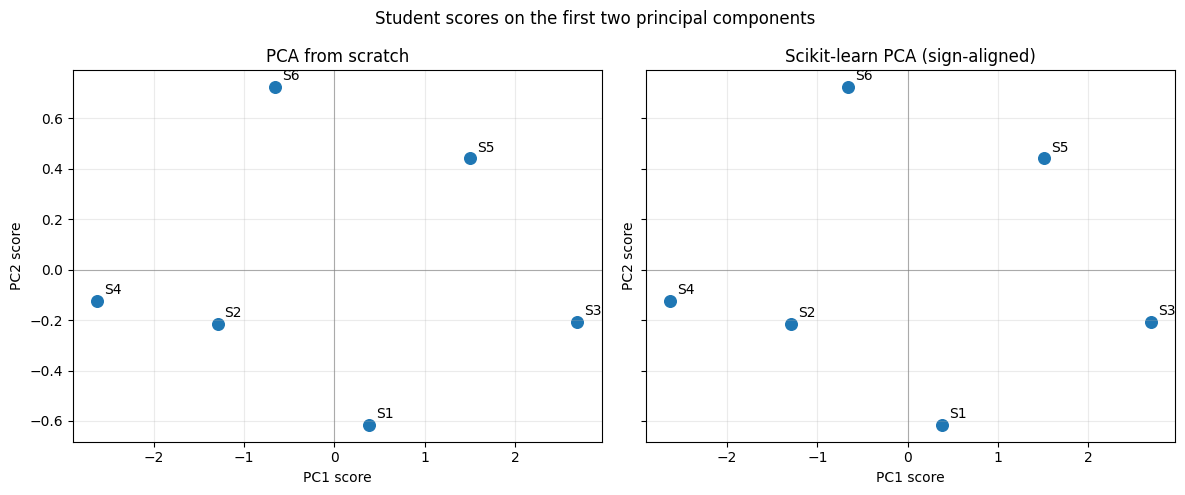

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
plot_data = [
    (scores_scratch, "PCA from scratch"),
    (pd.DataFrame(sklearn_scores_aligned, index=grades.index,
                  columns=["PC1", "PC2"]), "Scikit-learn PCA (sign-aligned)"),
]
for ax, (coordinates, title) in zip(axes, plot_data):
    ax.scatter(coordinates["PC1"], coordinates["PC2"], s=70)
    for student, row in coordinates.iterrows():
        ax.annotate(student, (row["PC1"], row["PC2"]), xytext=(5, 5),
                    textcoords="offset points")
    ax.axhline(0, color="gray", linewidth=0.8, alpha=0.6)
    ax.axvline(0, color="gray", linewidth=0.8, alpha=0.6)
    ax.set_title(title)
    ax.set_xlabel("PC1 score")
    ax.set_ylabel("PC2 score")
    ax.grid(alpha=0.25)
fig.suptitle("Student scores on the first two principal components")
fig.tight_layout()
plt.show()

### 3. Interpretation

- The two methods should produce the same eigenvalues, explained variance ratios, and student positions up to floating-point rounding and possible component sign changes.
- A sign reversal reflects the fact that an eigenvector and its negative are both valid representations of the same principal direction. Before alignment, the corresponding score axis may be mirrored; pairwise geometry and variance explained remain unchanged.
- The percentage of total variance retained by the first two components is printed above as the sum of their explained variance ratios multiplied by 100. This is the information retained when representing these four standardized subject grades in two dimensions.